# 0.6 Manifolds — 動手玩

這個 notebook 帶你**操作** `scw.manifold`：切空間、metric、flat/sharp，
以及把圓球面上的切向量畫出來。每個 code cell 都可以直接改數字重跑。


In [1]:
%matplotlib inline
import numpy as np
from scw.math_core import Covector
from scw.manifold import EuclideanSpace, Sphere
from scw.visualization import new_figure, new_3d_figure, plot_function, plot_vectors_3d


## 1. 平坦空間：切空間就是普通的向量空間

切向量是普通 `Vector`，但「記得」自己在哪一點；不同點的切向量不能相加。


In [2]:
plane = EuclideanSpace(3, name="E")
p = (1.0, 2.0, 3.0)
print("T_pM =", plane.tangent_space(p))
u = plane.tangent_vector([1.0, 0.0, 0.0], point=p)
w = plane.tangent_vector([0.0, 2.0, 0.0], point=p)
print("u + w =", (u + w).data)
q = (1.0, 2.0, 4.0)
try:
    u + plane.tangent_vector([1.0, 0.0, 0.0], point=q)
except Exception as exc:
    print("不同點相加被擋下:", type(exc).__name__)


T_pM = T_(1.0, 2.0, 3.0)E
u + w = [1. 2. 0.]
不同點相加被擋下: DimensionError


## 2. Metric：內積、長度、以及 flat / sharp 音樂同構

`flat` 把切向量降成餘切餘向量，`sharp` 再升回來，兩者互為逆。


In [3]:
g = plane.metric(p)
print("G =", g.components.tolist())
print("g(u, w) =", g.inner(u, w), " |u| =", g.norm(u))
alpha = g.flat(u)
print("flat(u) =", alpha.data, "(在對偶空間)")
print("sharp(flat(u)) = u ?", np.allclose(g.sharp(alpha).data, u.data))


G = [[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]]
g(u, w) = 0.0  |u| = 1.0
flat(u) = [1. 0. 0.] (在對偶空間)
sharp(flat(u)) = u ? True


## 3. 圓球面：彎曲的 metric

球面座標 `(theta, phi)` 的標準 metric 是 `diag(r^2, r^2 sin^2 theta)`；
`g_phiphi` 在兩極退化為 0（座標奇異點，會被拒絕）。


In [4]:
sphere = Sphere(radius=2.0)
theta, phi = np.pi / 2, 0.0  # 赤道上一點
gs = sphere.metric((theta, phi))
print("赤道 metric =", gs.components.tolist())
e_theta = sphere.tangent_vector([1.0, 0.0], point=(theta, phi))
e_phi = sphere.tangent_vector([0.0, 1.0], point=(theta, phi))
print("g(e_theta, e_phi) =", gs.inner(e_theta, e_phi), "(正交)")
print("|e_theta| =", gs.norm(e_theta), "|e_phi| =", gs.norm(e_phi))
v = sphere.tangent_vector([1.0, 3.0], point=(theta, phi))
print("v =", v.data, "-> flat(v) =", gs.flat(v).data)


赤道 metric = [[4.0, 0.0], [0.0, 4.0]]
g(e_theta, e_phi) = 0.0 (正交)
|e_theta| = 2.0 |e_phi| = 2.0
v = [1. 3.] -> flat(v) = [ 4. 12.]


## 4. metric 如何隨緯度變化

`g_phiphi = r^2 sin^2 theta`：赤道最長，越靠兩極越短（在極點歸零）。


Text(0.5, 1.0, 'sphere metric component vs polar angle')

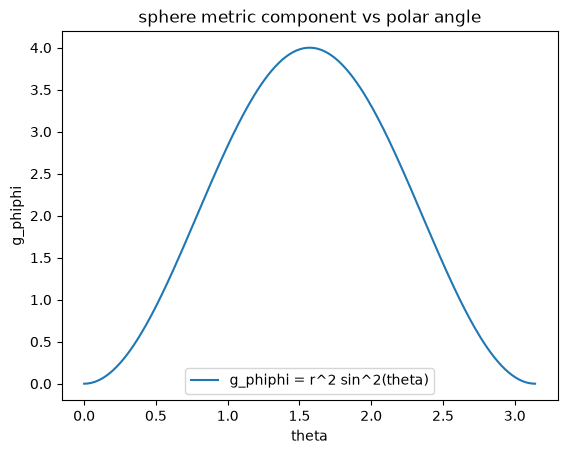

In [5]:
fig, ax = new_figure()
plot_function(lambda t: 4.0 * np.sin(t) ** 2, x_range=(0.0, np.pi), ax=ax,
              label="g_phiphi = r^2 sin^2(theta)")
ax.set_xlabel("theta"); ax.set_ylabel("g_phiphi"); ax.legend()
ax.set_title("sphere metric component vs polar angle")


## 5. 把球面與切向量畫成 3D 圖

把 `(theta, phi)` 座標嵌回 R^3，並畫出 `e_theta` 與 `e_phi` 兩個切向量。


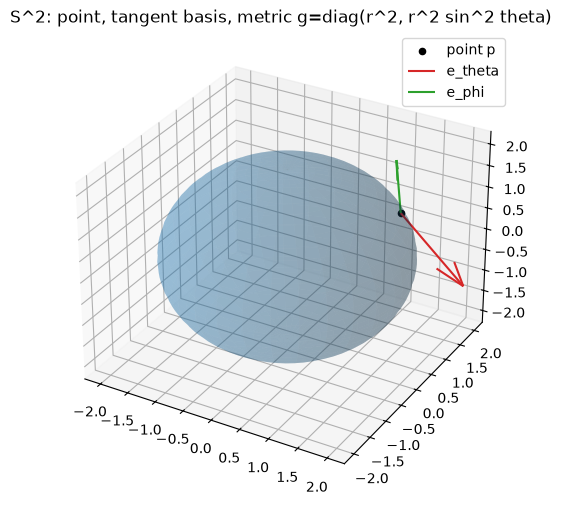

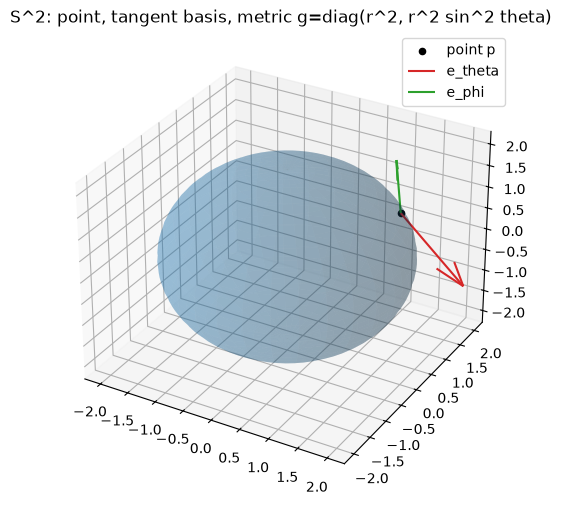

In [6]:
r = 2.0
def embed(th, ph):
    return np.array([r*np.sin(th)*np.cos(ph), r*np.sin(th)*np.sin(ph), r*np.cos(th)])

th0, ph0 = np.pi / 3, np.pi / 6
pt3 = embed(th0, ph0)
# 切向量的 3D 分量（座標基底 e_theta, e_phi）
e_th = np.array([r*np.cos(th0)*np.cos(ph0), r*np.cos(th0)*np.sin(ph0), -r*np.sin(th0)])
e_ph = np.array([-r*np.sin(th0)*np.sin(ph0), r*np.sin(th0)*np.cos(ph0), 0.0])

fig, ax = new_3d_figure(figsize=(6, 6))
TH, PH = np.meshgrid(np.linspace(0, np.pi, 60), np.linspace(0, 2*np.pi, 60))
ax.plot_surface(r*np.sin(TH)*np.cos(PH), r*np.sin(TH)*np.sin(PH), r*np.cos(TH),
                alpha=0.25, color="tab:blue", linewidth=0)
ax.scatter(*pt3, color="k", s=20, label="point p")
from scw.math_core import Vector
plot_vectors_3d([Vector(e_th), Vector(e_ph)], origins=[pt3, pt3],
                colors=["tab:red", "tab:green"], labels=["e_theta", "e_phi"], ax=ax)
ax.set_title("S^2: point, tangent basis, metric g=diag(r^2, r^2 sin^2 theta)")
ax.legend(loc="upper right")
fig


## 6. 換你玩

試著改：

- `sphere = Sphere(radius=...)` 換半徑，看 `|e_theta|`、`|e_phi|` 怎麼變。
- 把 `theta` 調靠近 0（極點），看 `g_phiphi` 如何趨近 0。
- 對 `Sphere` 用非對角 metric（例如加一個 `g_theta_phi` 項）丟進 `Metric`，
  試試 `flat`/`sharp` 是否仍互逆。
